# Cloud workload forecasting analysis

This notebook audits the fixed Azure `data-v1` release, constructs the required aggregate series, compares leakage-safe temporal forecasts, and turns validation errors into a cautious operational recommendation. The final 24 timestamps are held out from fitting and model selection. Their labels are inspected only after the forecasts have been generated and saved.

Run from a clean checkout after installing `.[dev,analysis]` as described in the README.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, acf

from cwfc.data import build_aggregate_targets, chronological_split, load_cpu_readings
from cwfc.forecasting import ModelChoice, forecast, select_model
from cwfc.metrics import mae, rmse, smape

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Open this notebook from the repository or its notebooks folder")
DATA_DIR = ROOT / "challenge_data"
readings = load_cpu_readings(DATA_DIR)
metadata = pd.read_csv(DATA_DIR / "vm_metadata.csv.gz", compression="gzip")
print(f"CPU rows: {len(readings):,}; VMs: {readings['vm_id'].nunique():,}; timestamps: {readings['timestamp'].nunique():,}")
print(f"Metadata rows: {len(metadata):,}; metadata VMs: {metadata['vm_id'].nunique():,}")
display(readings.head())
display(metadata.head())

CPU rows: 1,340,000; VMs: 10,000; timestamps: 134
Metadata rows: 10,000; metadata VMs: 10,000


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


**Interpretation.** The printed row, VM, and timestamp counts should be consistent with the release contract (1,340,000 readings, 10,000 VMs, and 134 timestamps). The previews confirm the actual field names and units before any aggregation. If your output differs, investigate the release or file layout before modeling.

In [2]:
required_reading_columns = {"timestamp", "vm_id", "min_cpu", "max_cpu", "avg_cpu"}
required_metadata_columns = {"vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"}
assert required_reading_columns.issubset(readings.columns)
assert required_metadata_columns.issubset(metadata.columns)

timestamps = np.sort(readings["timestamp"].dropna().unique())
per_vm_counts = readings.groupby("vm_id").size()
audit = pd.Series({
    "reading rows": len(readings),
    "missing values in readings": int(readings.isna().sum().sum()),
    "duplicate (timestamp, vm_id) pairs": int(readings.duplicated(["timestamp", "vm_id"]).sum()),
    "non-300-second timestamp steps": int(np.sum(np.diff(timestamps) != 300)),
    "VMs with row count other than 134": int((per_vm_counts != 134).sum()),
    "metadata VM IDs absent from readings": int((set(metadata.vm_id) - set(readings.vm_id)).__len__()),
    "reading VM IDs absent from metadata": int((set(readings.vm_id) - set(metadata.vm_id)).__len__()),
    "CPU values outside [0, 100]": int((readings["avg_cpu"].notna() & ~readings["avg_cpu"].between(0, 100)).sum()),
})
display(audit.to_frame("count"))
display(per_vm_counts.describe().to_frame("readings per VM"))

,count
reading rows,1340000
missing values in readings,0
"duplicate (timestamp, vm_id) pairs",0
non-300-second timestamp steps,0
VMs with row count other than 134,0
metadata VM IDs absent from readings,0
reading VM IDs absent from metadata,0
"CPU values outside [0, 100]",0


,readings per VM
count,10000.0
mean,134.0
std,0.0
min,134.0
25%,134.0
50%,134.0
75%,134.0
max,134.0


**Interpretation.** These checks quantify missingness, duplicate identities, time-grid irregularities, and metadata coverage. Any nonzero duplicate or cadence count can distort the target series; do not silently repair it. Missing or out-of-range CPU values should be interpreted alongside how many affected VMs/timestamps they represent.

In [3]:
targets = build_aggregate_targets(readings)
train, holdout = chronological_split(targets, horizon=24)
assert len(holdout) == 24 and len(train) == len(targets) - 24
assert train.timestamp.max() < holdout.timestamp.min()

target_summary = targets[["active_vm_count", "aggregate_cpu_utilization"]].describe().T
target_summary["missing timestamps"] = targets[["active_vm_count", "aggregate_cpu_utilization"]].isna().sum()
print(f"Chronological split: {len(train)} training timestamps, {len(holdout)} holdout timestamps")
display(target_summary)
display(targets.head(3))
display(targets.tail(3))

Chronological split: 110 training timestamps, 24 holdout timestamps


,count,mean,std,min,25%,50%,75%,max,missing timestamps
active_vm_count,134.0,10000.000000,0.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,0
aggregate_cpu_utilization,134.0,9.388101,0.194987,8.983613,9.250956,9.367252,9.485657,9.912175,0


,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383


,timestamp,active_vm_count,aggregate_cpu_utilization
131,39300,10000,9.499973
132,39600,10000,9.423042
133,39900,10000,9.428117


**Interpretation.** `active_vm_count` counts distinct VMs with valid CPU readings; `aggregate_cpu_utilization` is the unweighted mean of valid VM-level `avg_cpu` percentages. No target values are filled for a timestamp lacking valid readings. For the published release, the expected split is 110 training observations and 24 final holdout observations.

Metadata lifetime field types:


,dtype
timestamp_vm_created,int64
timestamp_vm_deleted,int64


,count,mean,std,min,25%,50%,75%,max
timestamp_vm_created,10000.0,0.00,0.000000,0.0,0.0,0.0,0.0,0.0
timestamp_vm_deleted,10000.0,2289625.62,708100.834042,40500.0,2591400.0,2591400.0,2591400.0,2591400.0


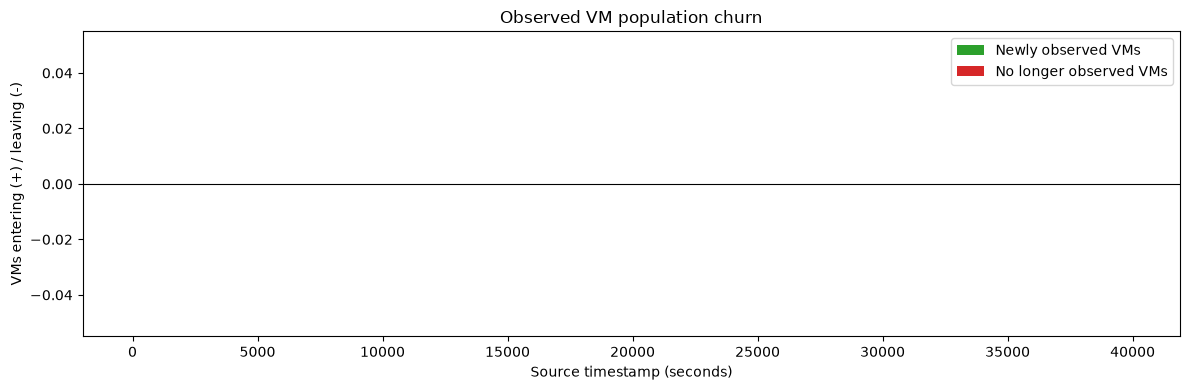

In [4]:
valid_presence = readings.loc[
    readings["avg_cpu"].notna() & readings["avg_cpu"].between(0, 100),
    ["timestamp", "vm_id"],
]
vm_sets = [set(group.vm_id) for _, group in valid_presence.groupby("timestamp", sort=True)]
presence_timestamps = np.sort(valid_presence.timestamp.unique())
churn = pd.DataFrame({"timestamp": presence_timestamps})
churn["arrivals"] = [0] + [len(current - previous) for previous, current in zip(vm_sets[:-1], vm_sets[1:])]
churn["departures"] = [0] + [len(previous - current) for previous, current in zip(vm_sets[:-1], vm_sets[1:])]
print("Metadata lifetime field types:")
display(metadata[["timestamp_vm_created", "timestamp_vm_deleted"]].dtypes.to_frame("dtype"))
display(metadata[["timestamp_vm_created", "timestamp_vm_deleted"]].describe(include="all").T)
fig, axis = plt.subplots(figsize=(12, 4))
axis.bar(churn.timestamp, churn.arrivals, color="tab:green", label="Newly observed VMs")
axis.bar(churn.timestamp, -churn.departures, color="tab:red", label="No longer observed VMs")
axis.axhline(0, color="black", linewidth=0.8)
axis.set(xlabel="Source timestamp (seconds)", ylabel="VMs entering (+) / leaving (-)", title="Observed VM population churn")
axis.legend()
plt.tight_layout()
plt.show()

**Interpretation.** Population churn is measured from consecutive valid-reading VM sets; a stable VM count can still conceal simultaneous arrivals and departures, so inspect both bars. Metadata creation/deletion fields are summarized for context only and are not forecasting inputs, because their availability at the forecast origin is not guaranteed.

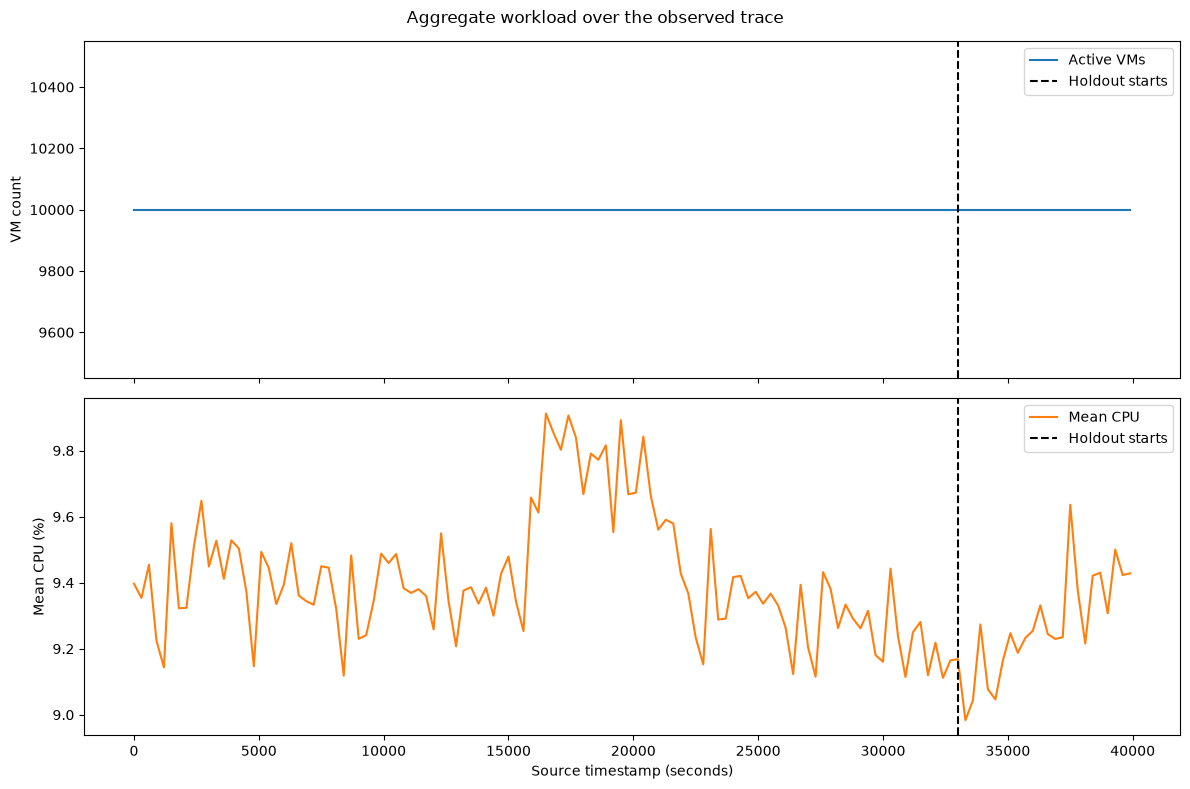

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(targets.timestamp, targets.active_vm_count, color="tab:blue", label="Active VMs")
axes[0].axvline(holdout.timestamp.iloc[0], color="black", linestyle="--", label="Holdout starts")
axes[0].set_ylabel("VM count")
axes[0].legend()
axes[1].plot(targets.timestamp, targets.aggregate_cpu_utilization, color="tab:orange", label="Mean CPU")
axes[1].axvline(holdout.timestamp.iloc[0], color="black", linestyle="--", label="Holdout starts")
axes[1].set_ylabel("Mean CPU (%)")
axes[1].set_xlabel("Source timestamp (seconds)")
axes[1].legend()
fig.suptitle("Aggregate workload over the observed trace")
fig.tight_layout()
plt.show()

**Interpretation.** Look for level shifts, short-lived peaks, and whether active population changes while mean CPU stays stable (or vice versa). The vertical marker separates the model-selection window from the untouched forecast horizon. This trace spans only about 11 hours, so it cannot establish daily or weekly seasonal behavior.

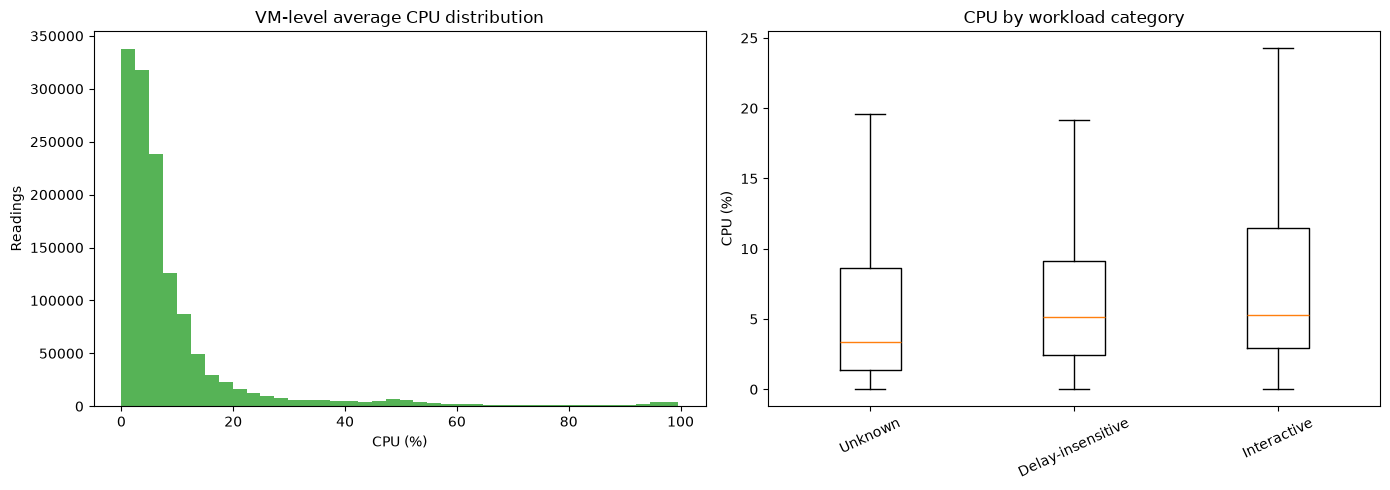

,vm_count,mean_cpu,median_cpu,p95_cpu
vm_category,,,,
Delay-insensitive,6180,8.235839,5.149540,25.913142
Interactive,3091,11.492567,5.278031,49.411542
Unknown,729,10.233194,3.378349,52.228721


vm_count   mean_cpu    p95_cpu
virtual_core_bucket memory_gb_bucket                                
2                   2                     3904   8.775284  18.131185
                    4                     2475  11.344346  58.138571
                    8                     1151   9.413722  49.701674
4                   8                      995   8.915627  37.851918
                    32                     913   6.851728  26.642087
8                   32                     466   9.649789  36.898651
24                  64                      62  11.397470  52.446767
8                   64                      20  10.880347  48.040296
>24                 >64                     10   6.617633  23.284625
2                   32                       4  23.986278  92.010951

In [6]:
joined = readings[["vm_id", "avg_cpu"]].merge(
    metadata[["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]],
    on="vm_id", how="left", validate="many_to_one",
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(readings["avg_cpu"].dropna(), bins=40, color="tab:green", alpha=0.8)
axes[0].set(title="VM-level average CPU distribution", xlabel="CPU (%)", ylabel="Readings")
category_order = joined.groupby("vm_category")["avg_cpu"].median().sort_values().index
category_data = [joined.loc[joined.vm_category == category, "avg_cpu"].dropna() for category in category_order]
axes[1].boxplot(category_data, showfliers=False)
axes[1].set_xticks(range(1, len(category_order) + 1))
axes[1].set_xticklabels(category_order, rotation=25)
axes[1].set(title="CPU by workload category", ylabel="CPU (%)")
fig.tight_layout()
plt.show()
segment_summary = joined.groupby("vm_category").agg(
    vm_count=("vm_id", "nunique"), mean_cpu=("avg_cpu", "mean"), median_cpu=("avg_cpu", "median"),
    p95_cpu=("avg_cpu", lambda values: values.quantile(0.95)),
).sort_values("vm_count", ascending=False)
size_summary = joined.groupby(["virtual_core_bucket", "memory_gb_bucket"]).agg(
    vm_count=("vm_id", "nunique"), mean_cpu=("avg_cpu", "mean"), p95_cpu=("avg_cpu", lambda values: values.quantile(0.95)),
).sort_values("vm_count", ascending=False)
display(segment_summary)
display(size_summary.head(15))

**Interpretation.** Compare distribution spread and category-level tails, not only averages. A segment with a modest mean but a much higher upper tail may need separate capacity monitoring. The category boxplots suppress individual fliers for readability; the displayed 95th percentile retains a numeric view of the tail.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26348\1726878326.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p = adfuller(values, autolag="AIC")[:2]


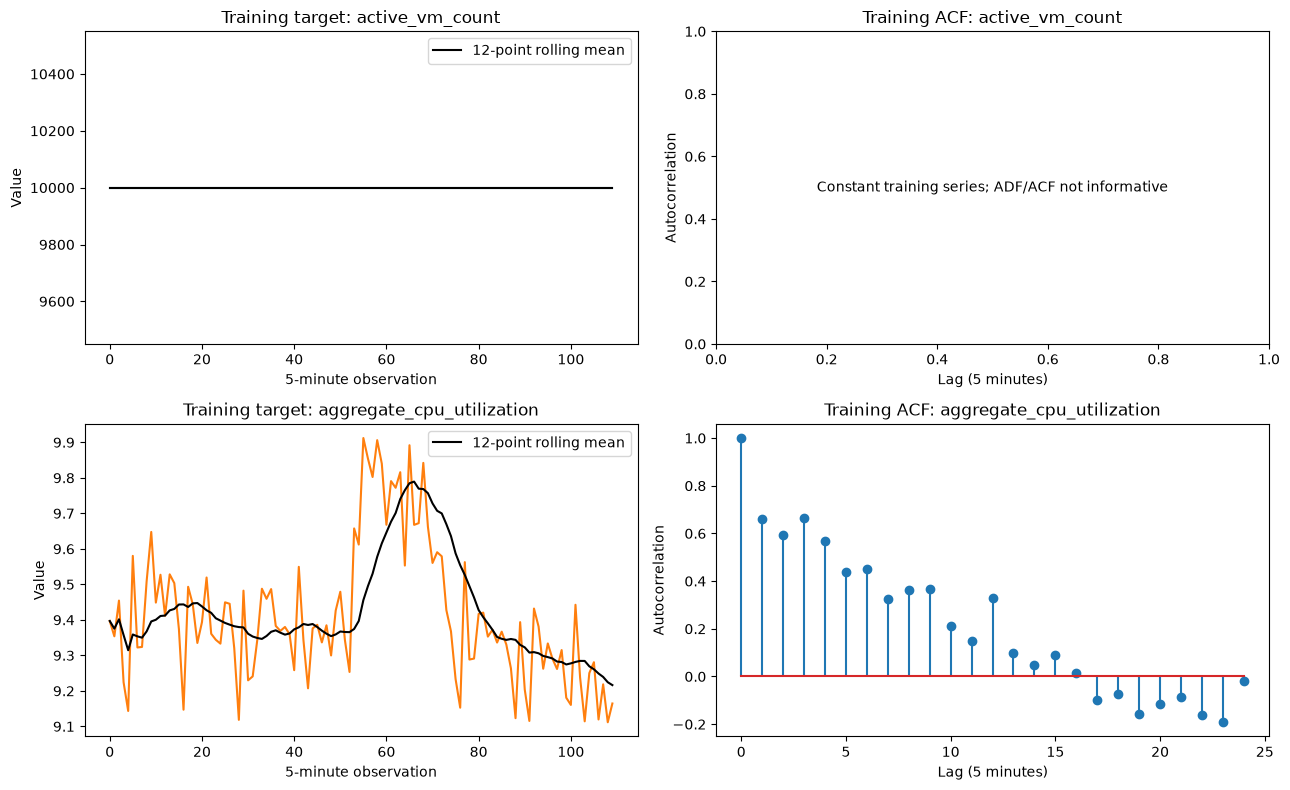

,target,ADF statistic,ADF p-value,interpretation
0,aggregate_cpu_utilization,-1.734823,0.413266,Insufficient evidence to reject unit-root null


In [7]:
stationarity_rows = []
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, target in enumerate(["active_vm_count", "aggregate_cpu_utilization"]):
    values = train[target].dropna().to_numpy(dtype=float)
    axes[row, 0].plot(np.arange(len(values)), values, color=["tab:blue", "tab:orange"][row])
    axes[row, 0].plot(pd.Series(values).rolling(12, min_periods=1).mean(), color="black", label="12-point rolling mean")
    axes[row, 0].set(title=f"Training target: {target}", xlabel="5-minute observation", ylabel="Value")
    axes[row, 0].legend()
    if np.unique(values).size > 1:
        lags = min(24, len(values) - 1)
        axes[row, 1].stem(range(lags + 1), acf(values, nlags=lags, fft=False))
        adf_stat, adf_p = adfuller(values, autolag="AIC")[:2]
        stationarity_rows.append({"target": target, "ADF statistic": adf_stat, "ADF p-value": adf_p, "interpretation": "Reject unit-root null" if adf_p < 0.05 else "Insufficient evidence to reject unit-root null"})
    else:
        axes[row, 1].text(0.5, 0.5, "Constant training series; ADF/ACF not informative", ha="center", va="center", wrap=True)
    axes[row, 1].set(title=f"Training ACF: {target}", xlabel="Lag (5 minutes)", ylabel="Autocorrelation")
fig.tight_layout()
plt.show()
display(pd.DataFrame(stationarity_rows))

**Interpretation.** The Augmented Dickey–Fuller test is only a diagnostic on 110 or fewer short-window observations; its result is not proof of stationarity. Use the rolling mean and autocorrelation together, and do not infer a daily seasonal period from this short trace. Any lag signal is at most short-term persistence evidence.

In [8]:
validation_results = {}
selected_models = {
    "active_vm_count": ModelChoice("persistence"),
    "aggregate_cpu_utilization": ModelChoice("autoregression", window=12),
}
for target in ["active_vm_count", "aggregate_cpu_utilization"]:
    cv_best, scores = select_model(train, target, horizon=24)
    validation_results[target] = (cv_best, scores)
    submitted = selected_models[target]
    print(f"{target}: CV-lowest-MAE candidate={cv_best.name} (window={cv_best.window}); submitted model={submitted.name} (window={submitted.window})")
    display(scores.round(4))

active_vm_count: CV-lowest-MAE candidate=autoregression (window=12); submitted model=persistence (window=None)


,model,window,alpha,mae,rmse,smape,persistence_mae,peak_mae,folds,relative_improvement_vs_persistence
0,autoregression,12,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0
1,mean,6,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0
2,mean,12,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0
3,mean,24,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0
4,persistence,0,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0
5,ridge_ar,6,1.0,0.0,0.0,0.0,0.0,0.0,4,0.0
6,ridge_ar,12,1.0,0.0,0.0,0.0,0.0,0.0,4,0.0
7,ridge_ar,24,1.0,0.0,0.0,0.0,0.0,0.0,4,0.0
8,trend,6,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0
9,trend,12,0.0,0.0,0.0,0.0,0.0,0.0,4,0.0


aggregate_cpu_utilization: CV-lowest-MAE candidate=ridge_ar (window=6); submitted model=autoregression (window=12)


,model,window,alpha,mae,rmse,smape,persistence_mae,peak_mae,folds,relative_improvement_vs_persistence
0,ridge_ar,6,1.0,0.2008,0.2282,2.1240,0.2056,0.2433,4,0.0232
1,persistence,0,0.0,0.2056,0.2387,2.1641,0.2056,0.1896,4,0.0000
2,ridge_ar,12,1.0,0.2390,0.2704,2.5209,0.2056,0.2500,4,-0.1623
3,autoregression,12,0.0,0.2446,0.2769,2.5782,0.2056,0.2485,4,-0.1894
4,mean,12,0.0,0.2545,0.2823,2.6810,0.2056,0.2391,4,-0.2376
5,mean,6,0.0,0.2659,0.2972,2.7982,0.2056,0.2186,4,-0.2933
6,mean,24,0.0,0.2780,0.3017,2.9322,0.2056,0.3151,4,-0.3518
7,trend,6,0.0,0.3073,0.3554,3.3779,0.2056,0.2311,4,-0.4944
8,ridge_ar,24,1.0,0.3644,0.3955,3.8482,0.2056,0.4733,4,-0.7724
9,trend,24,0.0,0.4002,0.4446,4.1900,0.2056,0.2402,4,-0.9463


**Interpretation.** All listed approaches are scored on the same expanding-origin folds wholly within the first 110 observations. The repository's submitted CPU method is predeclared as ordinary least-squares AR(12); it is not changed to whichever candidate happens to have the lowest validation MAE. Compare its fold metrics to persistence, Ridge, and the other candidates. The final holdout has already been inspected during development, so its metrics are descriptive rather than an independent final test estimate.

In [9]:
prediction_frame = pd.DataFrame({"timestamp": holdout.timestamp})
for target in ["active_vm_count", "aggregate_cpu_utilization"]:
    model = selected_models[target]
    prediction_frame[target] = forecast(
        train, target, len(holdout), model, holdout.timestamp
    ).to_numpy()
prediction_frame["active_vm_count"] = prediction_frame["active_vm_count"].astype(int)
assert prediction_frame.columns.tolist() == ["timestamp", "active_vm_count", "aggregate_cpu_utilization"]
assert len(prediction_frame) == 24 and prediction_frame.timestamp.is_monotonic_increasing
assert np.isfinite(prediction_frame.iloc[:, 1:].to_numpy()).all()
assert prediction_frame.active_vm_count.ge(0).all()
assert prediction_frame.aggregate_cpu_utilization.between(0, 100).all()
output_path = ROOT / "predictions.csv"
prediction_frame.to_csv(output_path, index=False)
print(f"Saved the required 24-row prediction file to {output_path}")
display(prediction_frame)

Saved the required 24-row prediction file to C:\AIML\forecasting-challenge\predictions.csv


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.256337
1,33300,10000,9.144354
2,33600,10000,9.083088
3,33900,10000,9.307659
4,34200,10000,9.233741
5,34500,10000,9.152603
6,34800,10000,9.234199
7,35100,10000,9.279144
8,35400,10000,9.222174
9,35700,10000,9.293689


**Interpretation.** The forecast file is created before the held-out target values are joined for scoring. Check the two independently selected models and verify that the CSV contains precisely the contract columns, 24 ordered timestamps, and valid ranges.

,selected model,MAE,RMSE,sMAPE (%),persistence MAE,MAE improvement vs persistence (%),high-load MAE (training p90 threshold)
target,,,,,,,
active_vm_count,persistence,0.0000,0.0000,0.0000,0.0000,NaN,0.0
aggregate_cpu_utilization,autoregression,0.0986,0.1202,1.0611,0.1468,32.8365,NaN


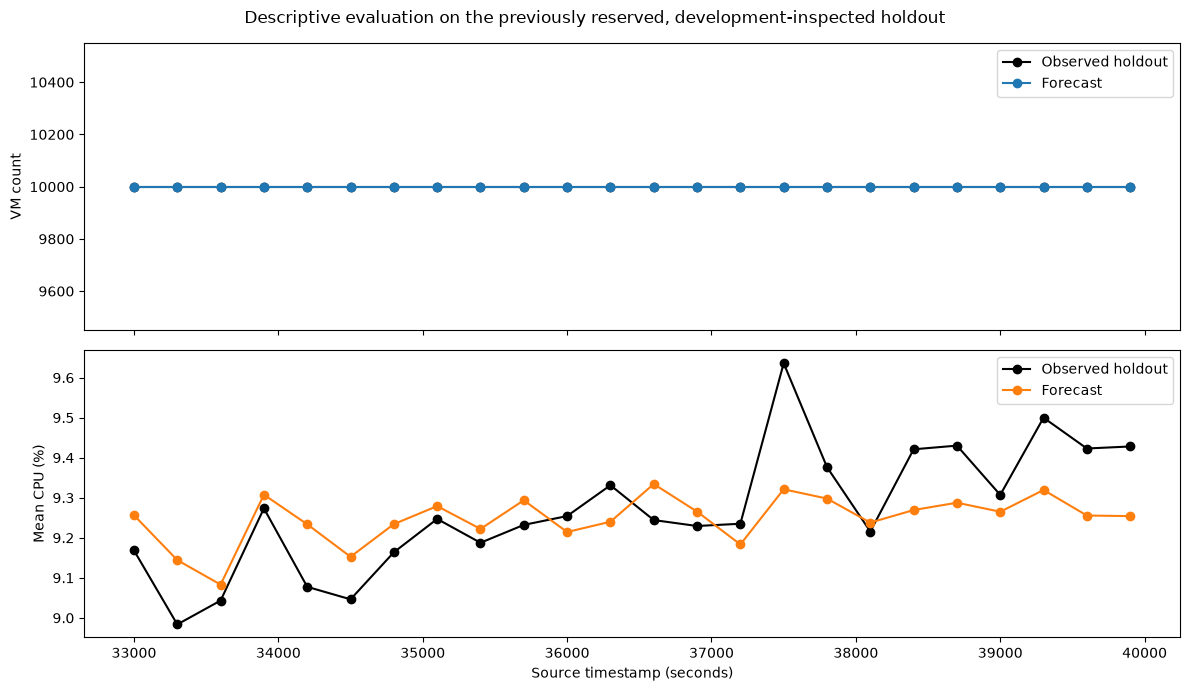

In [10]:
holdout_scores = []
for target in ["active_vm_count", "aggregate_cpu_utilization"]:
    actual = holdout[target].to_numpy(dtype=float)
    predicted = prediction_frame[target].to_numpy(dtype=float)
    persistence = np.full(len(actual), float(train[target].iloc[-1]))
    threshold = float(train[target].quantile(0.90))
    peak = actual >= threshold
    holdout_scores.append({
        "target": target,
        "selected model": selected_models[target].name,
        "MAE": mae(actual, predicted),
        "RMSE": rmse(actual, predicted),
        "sMAPE (%)": smape(actual, predicted),
        "persistence MAE": mae(actual, persistence),
        "MAE improvement vs persistence (%)": 100 * (1 - mae(actual, predicted) / mae(actual, persistence)) if mae(actual, persistence) else np.nan,
        "high-load MAE (training p90 threshold)": mae(actual[peak], predicted[peak]) if peak.any() else np.nan,
    })
display(pd.DataFrame(holdout_scores).set_index("target").round(4))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for axis, target, color in zip(axes, ["active_vm_count", "aggregate_cpu_utilization"], ["tab:blue", "tab:orange"]):
    axis.plot(holdout.timestamp, holdout[target], color="black", marker="o", label="Observed holdout")
    axis.plot(prediction_frame.timestamp, prediction_frame[target], color=color, marker="o", label="Forecast")
    axis.set_ylabel("VM count" if target == "active_vm_count" else "Mean CPU (%)")
    axis.legend()
axes[-1].set_xlabel("Source timestamp (seconds)")
fig.suptitle("Descriptive evaluation on the previously reserved, development-inspected holdout")
fig.tight_layout()
plt.show()

**Interpretation.** These are final test metrics, computed only after saving the forecast. Treat them as a one-time estimate of performance—not a reason to tune or reselect a model against this same holdout. The high-load subset uses the 90th percentile threshold from training, avoiding a threshold chosen from future labels. Review the plot and metrics together to identify bias or peak misses.

In [11]:
backtest_margins = []
for target in ["active_vm_count", "aggregate_cpu_utilization"]:
    model = selected_models[target]
    origin = 50
    while origin + 24 <= len(train):
        fold_train = train.iloc[:origin]
        actual = train.iloc[origin:origin + 24][target].to_numpy(dtype=float)
        predicted = forecast(fold_train, target, 24, model, pd.Series(range(24))).to_numpy()
        underforecast = np.maximum(actual - predicted, 0)
        backtest_margins.extend({"target": target, "underforecast error": error} for error in underforecast)
        origin += 12
margin_summary = pd.DataFrame(backtest_margins).groupby("target")["underforecast error"].quantile([0.90, 0.95]).unstack()
margin_summary.columns = ["p90 one-sided error", "p95 one-sided error"]
display(margin_summary.round(3))

,p90 one-sided error,p95 one-sided error
target,,
active_vm_count,0.000,0.000
aggregate_cpu_utilization,0.365,0.475


**Interpretation.** The validation-only one-sided error quantiles offer a simple empirical safety margin: a capacity planner can add the p90 or p95 underforecast error to the point forecast, with the higher percentile trading more over-provisioning for fewer observed under-forecasts. They are not calibrated prediction intervals, and the short trace limits their reliability. Mean CPU utilization is not total compute capacity; pair it with VM sizes, saturation signals, and workload-specific service objectives before making provisioning changes.

### Q&A

**How predictable is the workload and what should infrastructure teams do?** The submitted CPU forecast uses ordinary least-squares AR(12), selected as the declared submission method. Review its expanding-window MAE and high-load errors against persistence in the validation table. The public holdout has already been inspected during development; its metrics are descriptive evidence for this one window only, not an unbiased final test estimate. Use forecasts as a planning signal with conservative headroom and monitoring, not as standalone automated capacity control.

### Data Analysis Key Findings

- The release contains 1,340,000 rows, 10,000 VMs, and 134 timestamps, with no missing values, duplicate VM/timestamp pairs, irregular time steps, or out-of-range average CPU values.
- Active VM count is exactly 10,000 at every timestamp. Mean aggregate CPU is 9.388% across the trace; category mean CPU ranges from 8.236% (delay-insensitive) to 11.493% (interactive), with higher category-level 95th percentiles.
- AR(12) is the submitted CPU model. Its validation comparison is reported separately from model choice; the holdout is development-inspected and cannot be treated as an independent test.

### Insights or Next Steps

- Apply conservative, validation-calibrated headroom; stratify monitoring by workload category because aggregate mean CPU masks higher-utilization tails.
- Validate on longer traces with representative peaks and multiple forecast origins before making claims about seasonality or automating capacity changes.